# USD/INR forward-basis curve

Change settings and file names below. Raw files go in `raw/`; each completed run is saved in `results/`.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

import paths
import data_prep as dp
import curve_build as cb
import curve_model as cm
import curve_estimate as ce
import curve_drivers as cd
import risk_backtest as rb
import stress_turn as st
import curve_simulation as cs
import curve_turn_test as ct

## Settings

Edit file names here. All paths are relative to `raw/` unless  `PROJECT` is changed. `param_mode="saved"` uses an existing `params.csv`; choose `"fit"` to estimate again.

In [4]:
PROJECT = paths.HERE            # folder with the code, whatever the working directory
RAW = PROJECT / "raw"
TENORS = [f"{m}M" for m in range(1, 13)]

FILES = {
    "forwards": "FORWARD_PREMIA.csv",
    "ois": "fbil_mibor_ois.csv",
    "tbill": "tbillindia.csv",
    "us_par": "us_treasury_par_yield_1990_2023.csv",
    "us_1m": "DGS1MO.csv",
    "us_3m": "DGS3MO.csv",
    "us_6m": "DGS6MO.csv",
    "us_1y": "DGS1.csv",
    "curve": "basis_curve_long.csv",
    "params": "params.csv",
    "monthly": "panel_monthly.csv"
}

S = {
    "data_mode": "csv",             # raw or csv
    "param_mode": "saved",          # saved or fit
    "start": "2018-07-30",
    "end": None,
    "train_end": "2023-12-31",
    "test_start": "2024-01-01",
    "tenors": TENORS,
    "lambda": 0.30,
    "inr_rate": "ois",             # ois or tbill
    "us_switch": "2024-01-01",
    "fbd_fallback": False,
    "turn_walk": True,
    "use_fbd": True,
    "maxiter": 1000,
    "two_routes": False,
    "comparisons": False,
    "risk": True,
    "stress": True,
    "local_projections": True,
    "simulation": True,
    "turn_test": True,
    "null_simulation": True,
    "sim_reps": 10,
    "seed": 1000,
    "risk_tenors": TENORS,
    "risk_levels": [0.95, 0.99],
    "risk_window": 250,
    "risk_models": ["HS", "EWMA-normal", "EWMA-t-cal",
                    "SS-normal", "SS-t-EWMA", "SS-FHS"],
    "risk_lambda": 0.94,
    "risk_grid": [0.60, 0.70, 0.80, 0.85, 0.90, 0.94, 0.97],
    "stress_horizon": 10,
    "notional_usd": 10_000_000,
    "episodes": {
        "Covid 2020": ["2020-03-01", "2020-04-30"],
        "Dec 2025": ["2025-12-01", "2025-12-31"],
        "Mar-Apr 2026": ["2026-03-16", "2026-04-30"]
    },
    "lp_horizons": list(range(7)),
    "lp_se": "HAC",
    "save": True
}

if S["data_mode"] not in {"raw", "csv"}:
    raise ValueError("data_mode must be raw or csv")
if S["param_mode"] not in {"saved", "fit"}:
    raise ValueError("param_mode must be saved or fit")
if S["inr_rate"] not in {"ois", "tbill"}:
    raise ValueError("inr_rate must be ois or tbill")

# settings the saved params.csv was estimated with
SAVED_WITH = {"start": "2018-07-30", "train_end": "2023-12-31", "tenors": TENORS,
              "lambda": 0.30, "inr_rate": "ois", "us_switch": "2024-01-01"}

if S["comparisons"] and S["param_mode"] == "saved":
    print("Note: comparisons only run with param_mode = 'fit'")

print("Input folder:", RAW)
print("Data:", S["data_mode"], "| Parameters:", S["param_mode"])

Input folder: C:\Users\vinayak\Documents\fx\raw
Data: csv | Parameters: saved


## Basis data

In [6]:
inputs = []
checks = None
rate_checks = None

if S["data_mode"] == "csv":
    file = RAW / FILES["curve"]
    curve = pd.read_csv(file, parse_dates=["date"])
    inputs.append(file)
else:
    forward_file = RAW / FILES["forwards"]
    ois_file = RAW / FILES["ois"]
    tbill_file = RAW / FILES["tbill"]
    par_file = RAW / FILES["us_par"]
    fred_files = {"1M": RAW / FILES["us_1m"], "3M": RAW / FILES["us_3m"],
                  "6M": RAW / FILES["us_6m"], "12M": RAW / FILES["us_1y"]}
    inputs += [forward_file, ois_file, tbill_file, par_file, *fred_files.values()]

    ois_days = {"1M": 365/12, "2M": 365/6, "3M": 365/4,
                "6M": 365/2, "9M": 365*0.75, "1Y": 365}
    tbill_days = {"7 Days": 7, "14 Days": 14}
    for m in range(1, 13):
        name = "Month" if m == 1 else "Months"
        tbill_days[f"{m} {name}"] = 365*m/12

    forwards = dp.load_fbil_forwards(forward_file)
    ois = dp.load_long_curve(ois_file, ois_days, "Period", skiprows=2)
    tbill = dp.load_long_curve(tbill_file, tbill_days, "Tenor", skiprows=2)
    us = dp.load_us_treasury(par_file, fred_files, switch_date=S["us_switch"])
    inr = ois if S["inr_rate"] == "ois" else tbill

    curve, checks = cb.build(forwards, inr, us, ois, tbill,
                             start=S["start"], end=S["end"],
                             tenors=S["tenors"], fallback_april1=S["fbd_fallback"])
    bill_files = sorted(RAW.glob("us_treasury_bill_rates_*.csv"))
    bills = cb.load_us_bills(bill_files) if bill_files else None
    inputs += bill_files
    rate_checks = cb.rate_checks(curve, us, bills)

curve = curve.loc[curve["date"] >= S["start"]].copy()
if S["end"] is not None:
    curve = curve.loc[curve["date"] <= S["end"]]
curve = curve.sort_values(["date", "n"]).reset_index(drop=True)
outputs = {"basis_curve_long": curve, "curve_checks": checks,
           "rate_checks": rate_checks}
print(len(curve), "contracts on", curve["date"].nunique(), "dates")

25376 contracts on 1977 dates


## Estimation and factors

C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


,fit,loglik,converged
0,main,-49244.919674,None


,fiscal_year,rollover_date,pre_rollover_date,filtered_end_feb,filtered_pre_rollover,smoothed_median_oct_mar,observed_price_median,two_step
0,2019,2019-03-27,2019-03-26,7.593929,11.009834,4.647870,4.307475,4.985901
1,2020,2020-03-27,2020-03-26,6.728991,28.703865,14.061107,11.467313,15.339102
2,2021,2021-03-26,2021-03-25,17.980086,22.382318,18.042932,13.351604,18.165657
3,2022,2022-03-29,2022-03-28,9.448285,11.632895,17.162107,9.438314,17.807794
4,2023,2023-03-28,2023-03-27,9.265594,4.577658,10.492182,6.158586,9.624695
5,2024,2024-03-26,2024-03-22,3.515381,-0.702690,7.652011,0.416044,7.548554
6,2025,2025-03-26,2025-03-25,4.517368,14.300536,3.944856,7.384890,3.588786
7,2026,2026-03-25,2026-03-24,8.171116,14.445140,9.036757,16.233276,9.388764


,estimate,days,corr_with_observed,rmse_bp,mean_gap_bp
0,"main model, filtered (uses FBD April)",82,0.957605,2.689395,0.946203
1,"curve-only model, filtered (excludes FBD April)",82,0.953539,3.126721,1.178457


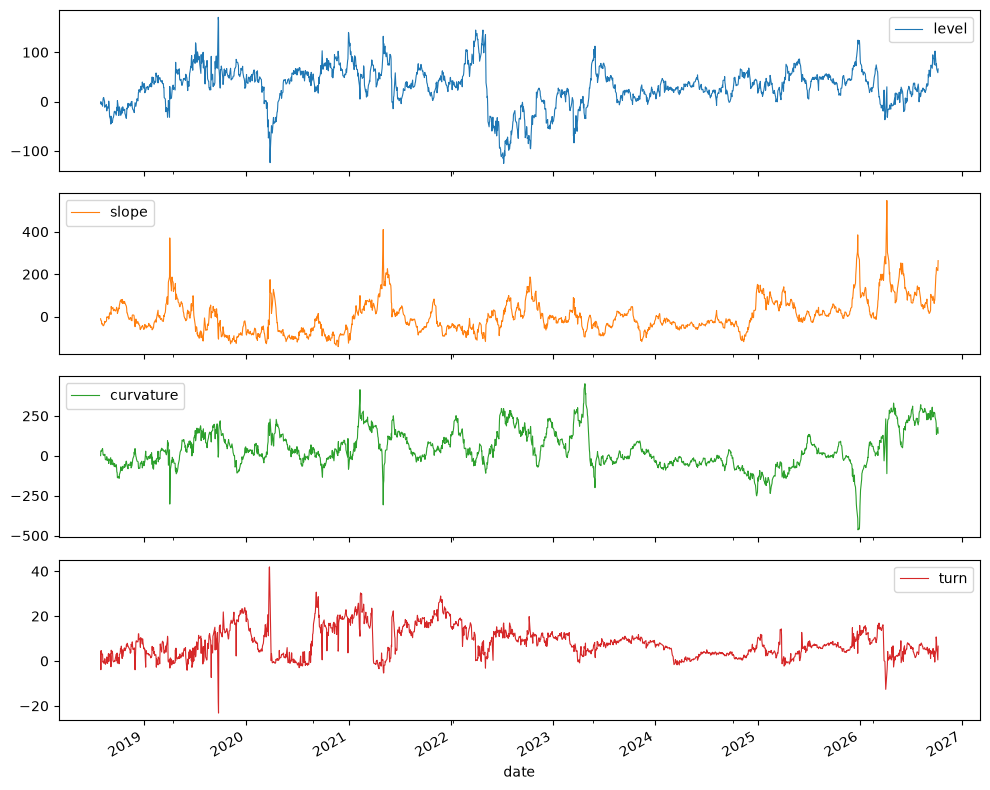

In [8]:
data = cm.load_curve(curve, S["tenors"])
train = cm.sample(data, S["start"], S["train_end"])
names = cm.parameter_names(S["tenors"])
fits = None

if S["param_mode"] == "saved":
    changed = [k for k, v in SAVED_WITH.items() if S[k] != v]
    if changed:
        raise ValueError(f"Saved parameters don't match settings {changed}; use param_mode='fit'")
    file = RAW / FILES["params"]
    table = pd.read_csv(file, index_col=0)
    inputs.append(file)
    columns = {(True, True): "main", (False, True): "one_charge_per_season",
               (True, False): "curve_only"}
    column = columns.get((S["turn_walk"], S["use_fbd"]))
    if column is None:
        raise ValueError("This variant needs param_mode='fit'")
    params = table.loc[names, column].to_numpy(dtype=float)
    llf = cm.run_filter(params, train, S["lambda"], S["use_fbd"]).llf
    summary = pd.DataFrame([{"fit": column, "loglik": llf,
                             "converged": None}])
else:
    fits, table, summary = ce.estimate(
        train, lam=S["lambda"], maxiter=S["maxiter"],
        two_routes=S["two_routes"], comparisons=S["comparisons"],
        turn_walk=S["turn_walk"], use_fbd=S["use_fbd"])
    params = table.loc[names, "main"].to_numpy(dtype=float)
    llf = fits["main"].llf

curve_only = table.loc[names, "curve_only"].to_numpy(dtype=float) if (
    S["turn_walk"] and S["use_fbd"] and "curve_only" in table) else None
out = ce.analyse(data, params, curve_only_params=curve_only,
                 lam=S["lambda"], use_fbd=S["use_fbd"])

outputs.update({"params": table, "fit_summary": summary})
for key in ["filtered", "smoothed", "one_step", "fit_by_tenor",
            "innovation_corr", "turn_by_year", "turn_validation", "observed_turn"]:
    outputs[key] = out[key]
outputs["innovation_white"] = out["innovation_white"]

display(summary)
display(out["turn_by_year"])
display(out["turn_validation"])
fig = out["filtered"][cm.STATES].plot(subplots=True, figsize=(10, 8), lw=0.8)[0].figure
fig.tight_layout()
plt.show()

## Drivers

In [10]:
allocation = cd.covariance_allocation(data, tenors=S["tenors"])
persistence = cd.half_lives(pd.Series(params, index=names))
outputs.update({"covariance_allocation": allocation,
                "factor_half_lives": persistence})
display(persistence)

if S["local_projections"]:
    file = RAW / FILES["monthly"]
    monthly = pd.read_csv(file, index_col="date", parse_dates=True)
    inputs.append(file)
    lp = cd.projections(out["smoothed"], cd.prepare_drivers(monthly),
                        horizons=S["lp_horizons"], se_type=S["lp_se"])
    outputs["local_projections"] = lp
    display(lp)

,factor,phi_daily,half_life_trading_days,at_upper_limit
0,level,0.974144,26.459564,False
1,slope,0.976531,29.186906,False
2,curvature,0.974888,27.253667,False


,factor,driver,h_months,response_bp,se_HC1,se_HAC,lower_90,upper_90,N,lags
0,level,rbi_spot,0,0.283112,0.539821,0.477633,-0.502594,1.068819,95,2
1,level,rbi_spot,1,0.363551,0.753487,0.740250,-0.854160,1.581262,94,2
2,level,rbi_spot,2,0.412164,0.701360,0.519872,-0.443026,1.267354,93,2
3,level,rbi_spot,3,0.936150,0.799739,0.567118,0.003240,1.869059,92,2
4,level,rbi_spot,4,0.504752,0.898406,0.745384,-0.721405,1.730910,91,2
5,level,rbi_spot,5,0.641909,0.684382,0.619479,-0.377134,1.660952,90,2
6,level,rbi_spot,6,0.401711,0.634311,0.508523,-0.434809,1.238230,89,2
7,level,d_liq,0,-0.487347,3.340268,3.003223,-5.427648,4.452954,95,2
8,level,d_liq,1,-7.958944,4.122578,3.114390,-13.082116,-2.835772,94,2
9,level,d_liq,2,-5.422942,5.964824,5.063970,-13.753172,2.907289,93,2


## Risk and stress

In [12]:
if S["risk"]:
    years = out["turn_by_year"]
    turn_avg = years.loc[years["fiscal_year"] <= pd.Timestamp(S["train_end"]).year,
                         "two_step"].mean()
    risk = rb.run(out["one_step"], turn_avg, out["reset_days"],
                  tenors=S["risk_tenors"], levels=S["risk_levels"],
                  train_end=S["train_end"], test_start=S["test_start"],
                  window=S["risk_window"], models=S["risk_models"],
                  rm_lambda=S["risk_lambda"], ewma_grid=S["risk_grid"])
    for key in ["backtests", "loss_comparison", "tuning"]:
        outputs[f"risk_{key}"] = risk[key]
    for tenor, frame in risk["forecasts"].items():
        outputs[f"risk_forecasts_{tenor}"] = frame
    display(risk["backtests"])
    display(risk["loss_comparison"])

if S["stress"]:
    stress = st.run(data, out["filtered"], out["smoothed"],
                    observed=out["observed_turn"],
                    rollover_days=out["rollover_days"],
                    episodes=S["episodes"], horizon=S["stress_horizon"],
                    lam=S["lambda"], notional_usd=S["notional_usd"])
    for key in ["turn_now", "turn_by_year", "event_summary", "event_by_year"]:
        outputs[f"stress_{key}"] = stress[key]
    outputs["stress_scenarios"] = stress["stress_scenarios"]
    outputs["stress_raw"] = stress["stress_raw"]
    display(stress["turn_now"])
    display(stress["stress_scenarios"])

,tenor,level,model,days,expected,breaches,zone,kupiec_p,independence_p,es_test_stat,es_test_p,breaches_turn_window,mean_var
0,1M,0.95,HS,666,33.30,46,yellow,3.234015e-02,0.306504,3.007403,2.634900e-03,1,23.314789
1,1M,0.95,EWMA-normal,666,33.30,42,green,1.364442e-01,0.163737,3.279206,1.040996e-03,1,31.430481
2,1M,0.95,EWMA-t-cal,666,33.30,65,red,5.267374e-07,0.000204,6.126188,9.000937e-10,3,24.137777
3,1M,0.95,SS-normal,666,33.30,32,green,8.160873e-01,0.000340,1.623468,1.044894e-01,1,34.725751
4,1M,0.95,SS-t-EWMA,666,33.30,63,red,2.270648e-06,0.648082,6.395599,1.599187e-10,1,23.531108
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,12M,0.99,EWMA-normal,666,6.66,16,yellow,2.054772e-03,0.004602,5.425177,5.789702e-08,1,12.734698
140,12M,0.99,EWMA-t-cal,666,6.66,12,yellow,6.158200e-02,0.015142,0.810487,4.176606e-01,1,14.552900
141,12M,0.99,SS-normal,666,6.66,7,green,8.955230e-01,0.720970,0.260013,7.948536e-01,0,19.174873
142,12M,0.99,SS-t-EWMA,666,6.66,9,green,3.870448e-01,0.104516,1.302131,1.928718e-01,1,13.934091


,tenor,level,model,benchmark,tick_gain,tick_p,fz0_gain,fz0_p,tick_days,fz0_days,fz0_days_dropped
0,1M,0.95,HS,EWMA-normal,-0.057740,0.699256,-0.142385,0.299526,666,666,0
1,1M,0.95,EWMA-t-cal,EWMA-normal,-0.395457,0.177308,-0.004999,0.969426,666,663,3
2,1M,0.95,SS-normal,EWMA-normal,-0.225391,0.344331,-0.625096,0.111494,666,662,4
3,1M,0.95,SS-t-EWMA,EWMA-normal,0.046275,0.777007,0.156561,0.268524,666,664,2
4,1M,0.95,SS-FHS,EWMA-normal,0.166850,0.286895,0.351539,0.016559,666,664,2
...,...,...,...,...,...,...,...,...,...,...,...
283,12M,0.99,SS-normal,HS,-0.003240,0.898561,0.137038,0.562149,666,666,0
284,12M,0.99,SS-t-EWMA,HS,0.042297,0.257901,0.422623,0.226771,666,666,0
285,12M,0.99,SS-FHS,HS,0.042803,0.258821,0.384277,0.275767,666,666,0
286,12M,0.99,SS-t-EWMA,EWMA-t-cal,0.018561,0.274570,0.073256,0.598199,666,666,0


,as_of,turn,estimate_bp,lo90_bp,hi90_bp,estimate_paise,lo90_paise,hi90_paise
0,2026-10-06,31 March 2027,6.587926,3.183798,9.992054,6.351558,3.069567,9.633549


,episode,window,tenor,change_bp,paise_per_usd,inr_lakh_for_notional
0,Covid 2020,2020-03-11 to 2020-03-26,1M,168.464366,14.239565,14.239565
1,Covid 2020,2020-03-11 to 2020-03-26,2M,149.603897,24.105238,24.105238
2,Covid 2020,2020-03-11 to 2020-03-26,3M,130.367363,31.680745,31.680745
3,Covid 2020,2020-03-11 to 2020-03-26,4M,112.402980,36.519230,36.519230
4,Covid 2020,2020-03-11 to 2020-03-26,5M,97.397905,38.847694,38.847694
5,Covid 2020,2020-03-11 to 2020-03-26,6M,82.173077,39.503868,39.503868
6,Covid 2020,2020-03-11 to 2020-03-26,7M,67.953496,38.411764,38.411764
7,Covid 2020,2020-03-11 to 2020-03-26,8M,56.311687,36.144605,36.144605
8,Covid 2020,2020-03-11 to 2020-03-26,9M,45.424819,32.756277,32.756277
9,Covid 2020,2020-03-11 to 2020-03-26,10M,34.997973,28.195605,28.195605


## Simulation and turn test

In [14]:
null = None
needs_full = S["simulation"] or S["null_simulation"] or S["turn_test"]
if needs_full and not (S["turn_walk"] and S["use_fbd"]):
    raise ValueError("Simulation and turn test need turn_walk = True and use_fbd = True")

if S["simulation"]:
    sim = cs.run(train, params, scenario="baseline", reps=S["sim_reps"],
                 seed=S["seed"], lam=S["lambda"], maxiter=S["maxiter"],
                 two_routes=S["two_routes"])
    for key in ["params", "states", "turn_by_month"]:
        outputs[f"sim_{key}"] = sim[key]
    display(sim["params"])

if S["null_simulation"]:
    null = cs.run(train, params, scenario="no_turn", reps=S["sim_reps"],
                  seed=S["seed"], lam=S["lambda"], maxiter=S["maxiter"],
                  two_routes=S["two_routes"])
    for key in ["params", "states", "turn_by_month"]:
        outputs[f"null_{key}"] = null[key]
    display(null["params"])

if S["turn_test"]:
    converged = None if fits is None else bool(fits["main"].mle_retvals.get("converged"))
    turn_test = ct.run(train, params, llf, null_simulations=null,
                       seed=S["seed"], lam=S["lambda"],
                       maxiter=S["maxiter"], full_converged=converged)
    outputs["turn_lr_test"] = turn_test
    display(turn_test[["sample", "LR", "mc_p_value", "mc_reps"]])

C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
 

,rep,loglik,converged,at_bound,phi_L,phi_S,phi_C,mu_L,mu_S,mu_C,...,sigma_9M,sigma_10M,sigma_11M,sigma_12M,sigma_fbd,mu_D,sigma_w,sigma_xi,rho,kappa
0,0,-49100.326009,False,,0.982047,0.961988,0.973287,22.303462,-37.801638,59.807085,...,4.017833,2.741692,2.162163,4.376795,3.575184,-3.026729,2.757592,7.644195e-01,0.580014,0.442009
1,1,-49059.776324,True,,0.972141,0.977052,0.964981,24.767174,9.524049,87.507075,...,4.226719,2.785863,2.249903,4.647972,3.573061,-1.302056,2.699063,3.022172e-07,0.585909,0.501488
2,2,-49167.691969,True,,0.974516,0.973589,0.967719,27.275022,-10.606765,52.213640,...,3.913579,2.805049,2.238880,4.323626,3.798753,-2.061020,2.645895,4.046762e-03,0.581653,0.461986
3,3,-49298.757573,True,phi_S,0.979143,0.999000,0.974559,14.859638,-15.257254,91.020016,...,3.848308,2.849638,2.394235,4.375461,3.591882,-1.627172,2.610728,4.232112e-05,0.575771,0.472949
4,4,-49186.065084,True,,0.961591,0.964397,0.959423,27.752666,-3.234285,51.026500,...,3.964436,2.499923,0.000056,4.117460,3.602621,0.233385,2.538982,4.046643e-06,0.575445,0.439357
5,5,-49116.848664,True,phi_S,0.965515,0.999000,0.962754,18.322447,9.070486,51.717646,...,3.896126,2.684117,2.344447,4.550899,3.469183,-1.480414,2.668018,1.095823e-05,0.585503,0.464747
6,6,-49207.195537,True,phi_S phi_C,0.979440,0.998871,0.999000,37.735184,-21.844630,23.332645,...,4.230447,2.856692,2.474103,4.596199,3.813421,0.317179,2.699422,9.332683e-07,0.597562,0.495874
7,7,-49123.840609,True,,0.969791,0.968199,0.965234,26.504608,-31.093809,56.989990,...,3.956215,2.410204,0.000054,3.941422,3.778952,-0.668508,2.501062,7.988180e-06,0.569385,0.442082
8,8,-49148.336092,True,phi_S phi_C,0.992223,0.999000,0.998927,22.485041,-17.730204,85.394406,...,4.156262,2.726406,2.439409,4.431038,3.552572,1.776528,2.659904,1.055292e-05,0.581638,0.479363
9,9,-49307.830654,True,,0.969108,0.978464,0.969077,7.698036,8.023809,115.390285,...,3.938696,2.554000,0.000011,4.012176,3.688282,0.329274,2.799596,1.571572e-05,0.572966,0.437831


C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency informa

,rep,loglik,converged,at_bound,phi_L,phi_S,phi_C,mu_L,mu_S,mu_C,...,sigma_9M,sigma_10M,sigma_11M,sigma_12M,sigma_fbd,mu_D,sigma_w,sigma_xi,rho,kappa
0,0,-48234.191071,True,,0.982544,0.962458,0.973283,22.351858,-37.911532,59.854256,...,4.038340,2.743688,2.202430e+00,4.404666,3.584532,0.050251,6.263259e-37,8.941280e-07,0.577802,0.454730
1,1,-48290.462781,True,,0.963221,0.971321,0.955136,24.617012,9.484059,87.383150,...,4.019788,2.499462,2.445325e-16,4.059751,3.717172,-0.055612,5.392819e-26,1.440809e-05,0.586113,0.443554
2,2,-48362.941011,True,,0.969736,0.971477,0.962806,27.095994,-10.661449,52.109450,...,3.838152,2.570138,4.834513e-12,3.943567,3.842151,-0.154611,5.333155e-27,6.377448e-05,0.579211,0.435528
3,3,-48481.711015,True,phi_S phi_C,0.991210,0.998985,0.998954,14.656829,-15.235004,90.921048,...,3.877040,2.860927,2.419482e+00,4.390469,3.551722,-0.010739,3.907944e-40,4.756649e-06,0.574117,0.482105
4,4,-48457.499380,True,phi_L phi_S phi_C,0.999000,0.998950,0.999000,27.888002,-3.214845,51.057235,...,4.021110,2.547553,2.227310e-16,4.153767,3.661836,0.072996,7.967321e-28,1.366058e-03,0.578222,0.451643
5,5,-48294.070970,True,phi_S,0.960429,0.999000,0.956417,18.340432,9.068246,51.707216,...,3.840771,2.501783,1.630220e-13,4.084966,3.554277,0.025534,2.654474e-32,5.225532e-06,0.582313,0.447597
6,6,-48346.254675,True,phi_S,0.969856,0.999000,0.975502,38.045882,-21.851039,23.440375,...,4.214417,2.835669,2.449040e+00,4.560344,3.820856,0.007303,3.250274e-33,1.582829e-06,0.595288,0.489371
7,7,-48345.237174,True,phi_L phi_C,0.999000,0.979162,0.999000,26.778087,-31.045298,57.102404,...,3.984195,2.419200,1.795116e-13,3.979713,3.766064,0.125893,1.559743e-34,5.129010e-06,0.570847,0.451908
8,8,-48268.546498,True,phi_L phi_S phi_C,0.999000,0.999000,0.999000,22.408683,-17.737621,85.377765,...,4.149619,2.721177,2.480303e+00,4.429579,3.527730,-0.286869,1.113618e-39,1.776820e-06,0.578940,0.487035
9,9,-48474.410764,True,phi_L phi_S phi_C,0.999000,0.999000,0.998986,7.591998,8.032451,115.325893,...,3.945401,2.585347,1.287572e-22,4.024700,3.651136,0.090701,8.280694e-32,1.218230e-05,0.572779,0.446883


C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency informa

,sample,LR,mc_p_value,mc_reps
0,real data,5646.606097,0.090909,10
1,simulated no-turn rep 0,0.175528,NaN,0
2,simulated no-turn rep 1,0.212318,NaN,0
3,simulated no-turn rep 2,1.640262,NaN,0
4,simulated no-turn rep 3,0.008473,NaN,0
5,simulated no-turn rep 4,0.357790,NaN,0
6,simulated no-turn rep 5,0.037541,NaN,0
7,simulated no-turn rep 6,0.000000,NaN,0
8,simulated no-turn rep 7,1.109954,NaN,0
9,simulated no-turn rep 8,5.747468,NaN,0


## Save run

In [16]:
if S["save"]:
    folder = paths.new_run(PROJECT / "results")
    paths.save_run(folder, {"files": FILES, "settings": S}, outputs, inputs, PROJECT)
    fig.savefig(folder / "factors.png", dpi=140)
    print("Saved:", folder)

Saved: C:\Users\vinayak\Documents\fx\results\basis_run_20261023_214327_219334


basis_summary


,Mean,SD,Min,Max,SD daily change
tenor,,,,,
1M,45.8,84.6,-143.6,590.3,28.1
2M,48.6,71.1,-105.2,459.6,17.3
3M,52.0,64.2,-89.9,381.8,13.2
4M,53.0,58.7,-78.5,321.8,11.0
5M,53.5,54.8,-69.4,281.9,10.0
6M,53.9,52.0,-55.7,251.5,8.7
7M,53.4,49.8,-49.4,236.4,8.5
8M,52.3,47.6,-57.6,222.7,7.9
9M,51.3,45.4,-54.7,210.4,8.0


fit_summary


,fit,loglik,converged
0,main,-49244.919674,None


C:\Users\vinayak\anaconda3\envs\bayes_ssm\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


...

,Replications,Converged,Any parameter at bound
0,10,9,10


mc_states


rmse   bias  coverage_90
state     estimate                            
curvature filtered  52.813  0.589        0.882
          smoothed  45.007  0.876        0.890
level     filtered  14.979 -0.180        0.871
          smoothed  13.020 -0.207        0.877
slope     filtered  15.318  0.019        0.882
          smoothed  13.986 -0.035        0.884
turn      filtered   2.268  0.008        0.892
          smoothed   1.987 -0.011        0.895

turn_lr_test


,sample,LR,raw_LR
0,real data,5646.606,5646.606
1,simulated no-turn rep 0,0.176,0.176
2,simulated no-turn rep 1,0.212,0.212
3,simulated no-turn rep 2,1.640,1.640
4,simulated no-turn rep 3,0.008,0.008
5,simulated no-turn rep 4,0.358,0.358
6,simulated no-turn rep 5,0.038,0.038
7,simulated no-turn rep 6,0.000,-0.014
8,simulated no-turn rep 7,1.110,1.110
9,simulated no-turn rep 8,5.747,5.747


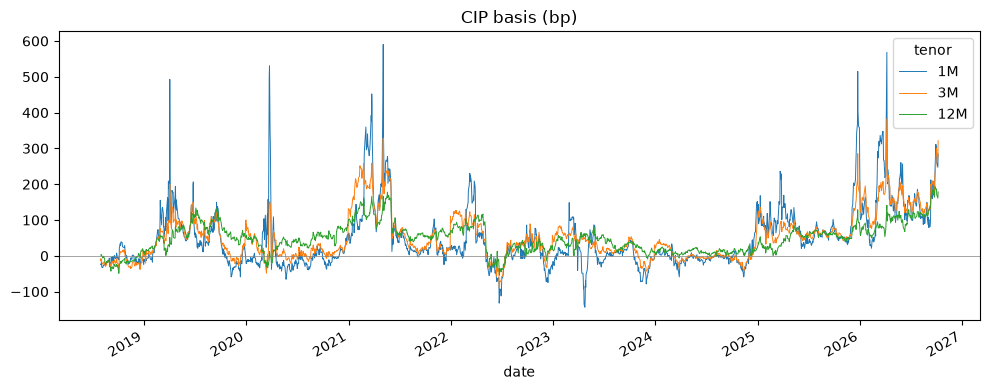

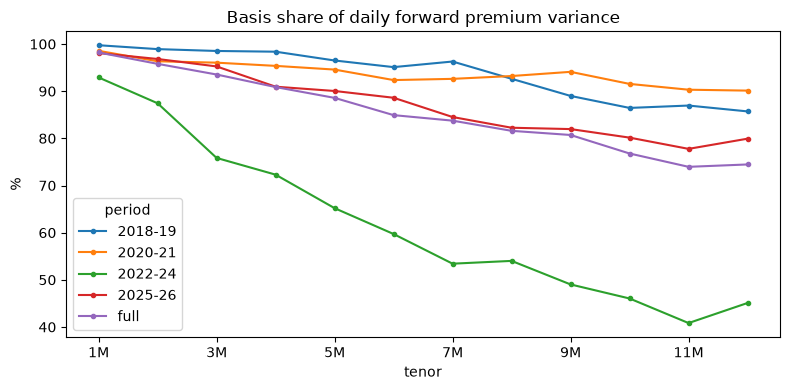

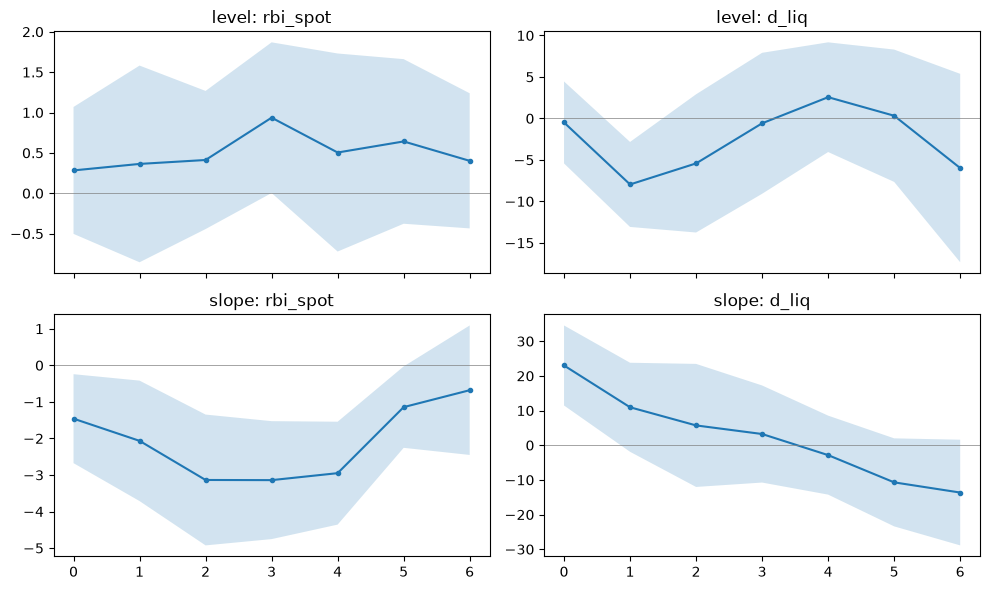

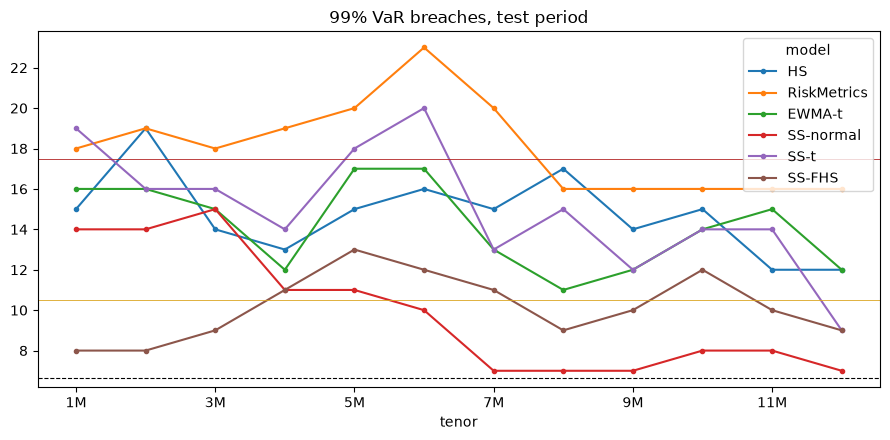

KeyError: "None of ['day'] are in the columns"

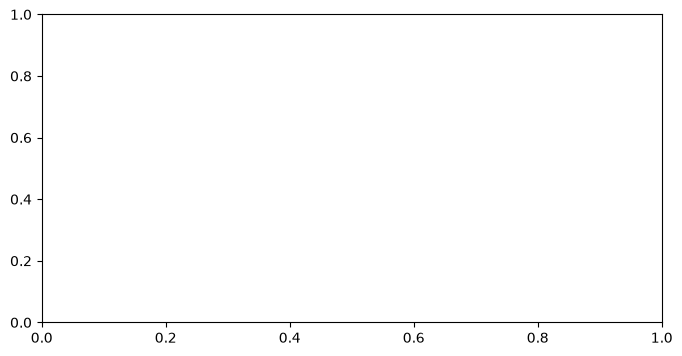

In [25]:
import report

where = folder if S["save"] else None
report.tables(S, where, data, train, params, names, summary, out, persistence, allocation,
              lp=lp if S["local_projections"] else None,
              risk=risk if S["risk"] else None,
              stress=stress if S["stress"] else None,
              sim=sim if S["simulation"] else None,
              turn_test=turn_test if S["turn_test"] else None)
report.figures(S, where, data, out, allocation,
               lp=lp if S["local_projections"] else None,
               risk=risk if S["risk"] else None,
               stress=stress if S["stress"] else None)

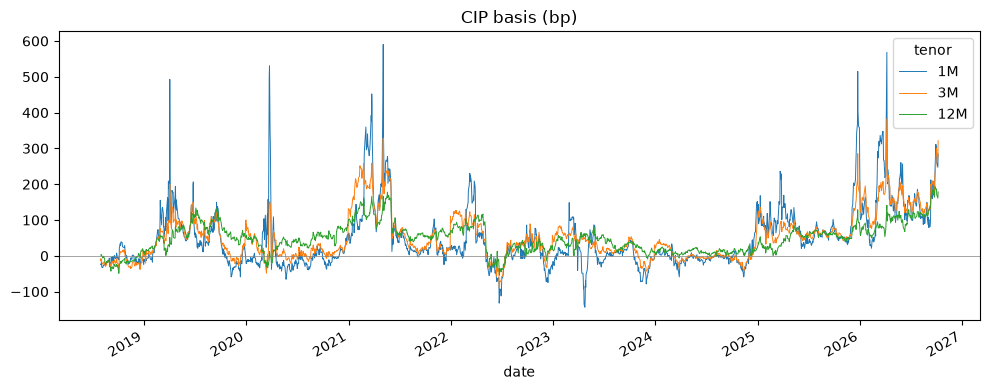

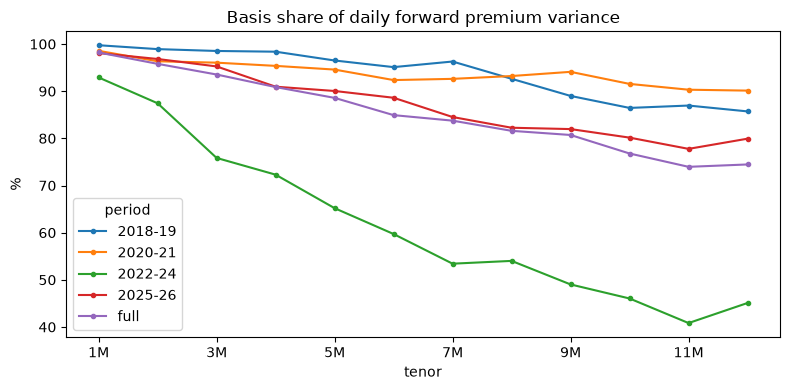

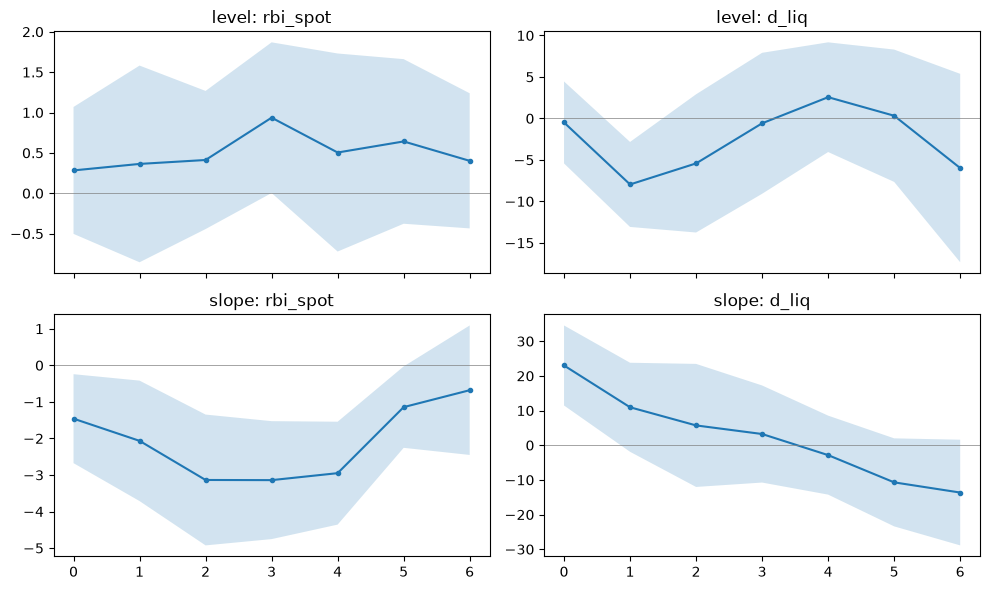

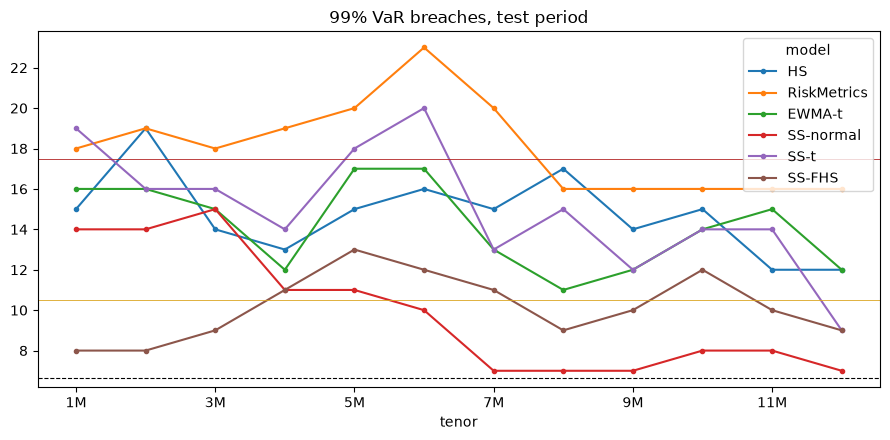

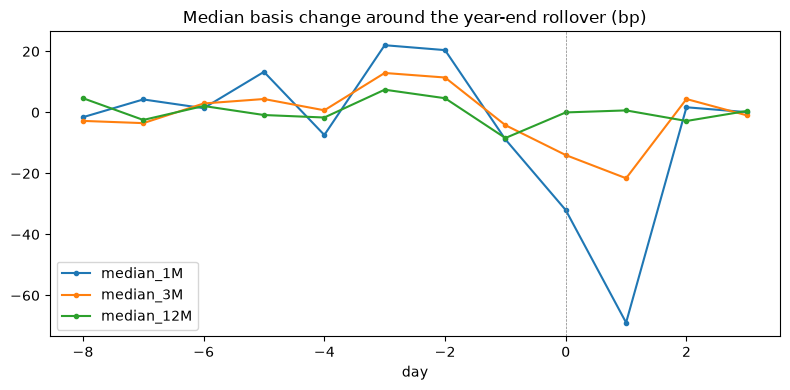

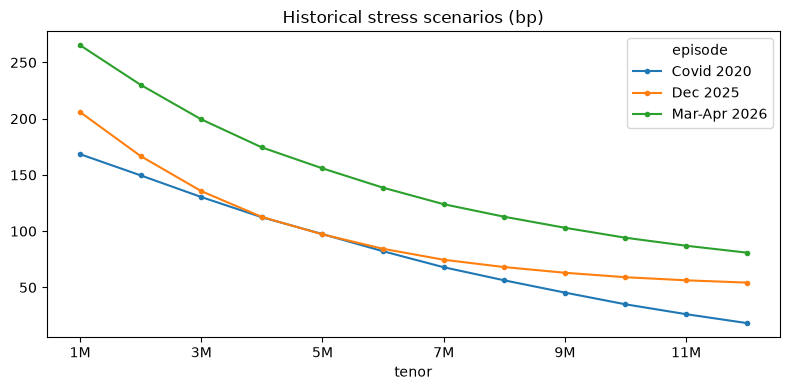

In [27]:
import importlib
importlib.reload(report)
report.figures(S, where, data, out, allocation,
               lp=lp if S["local_projections"] else None,
               risk=risk if S["risk"] else None,
               stress=stress if S["stress"] else None)